# Demo 3: Visual Question Answering — Qwen2-VL

**Model:** `Qwen/Qwen2-VL-7B-Instruct`  
**Task:** Ask free-form natural language questions about an image (multi-turn conversation supported)

---
**Flow:**
1. Load an image from file
2. Load Qwen2-VL model
3. Generate auto caption or ask custom questions


In [ ]:
# ── Imports ──────────────────────────────────────────────────────────────────
import os
# GPU Setting
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
import sys
sys.path.insert(0, '..')

import matplotlib.pyplot as plt
from PIL import Image
import cv2


import warnings
warnings.filterwarnings('ignore')

## Step 1: Load Image

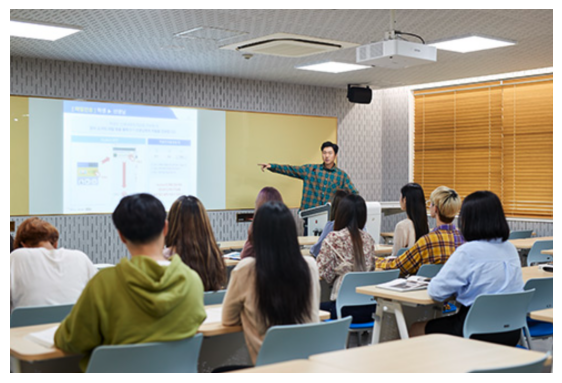

In [ ]:
# ── Load from file ──────────────────────────────────────────────────
IMAGE_PATH = "sample.png"
image = Image.open(IMAGE_PATH).convert("RGB")
plt.figure(figsize=(7, 5))
plt.imshow(image); plt.axis('off'); plt.show()

## Step 2: Load Qwen2-VL Model

In [4]:
from models.vlm_model import Qwen2VLQA

vlm = Qwen2VLQA()
vlm.load()   # downloads model on first run (~15 GB)

[Qwen2-VL] Loading Qwen/Qwen2-VL-7B-Instruct ...


The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.
You have video processor config saved in `preprocessor.json` file which is deprecated. Video processor configs should be saved in their own `video_preprocessor.json` file. You can rename the file or load and save the processor back which renames it automatically. Loading from `preprocessor.json` will be removed in v5.0.


Loading checkpoint shards:   0%|          | 0/5 [00:00<?, ?it/s]

[Qwen2-VL] Model loaded.


## Step 3: Auto Image Caption

Ask the model to describe the image without a specific question.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


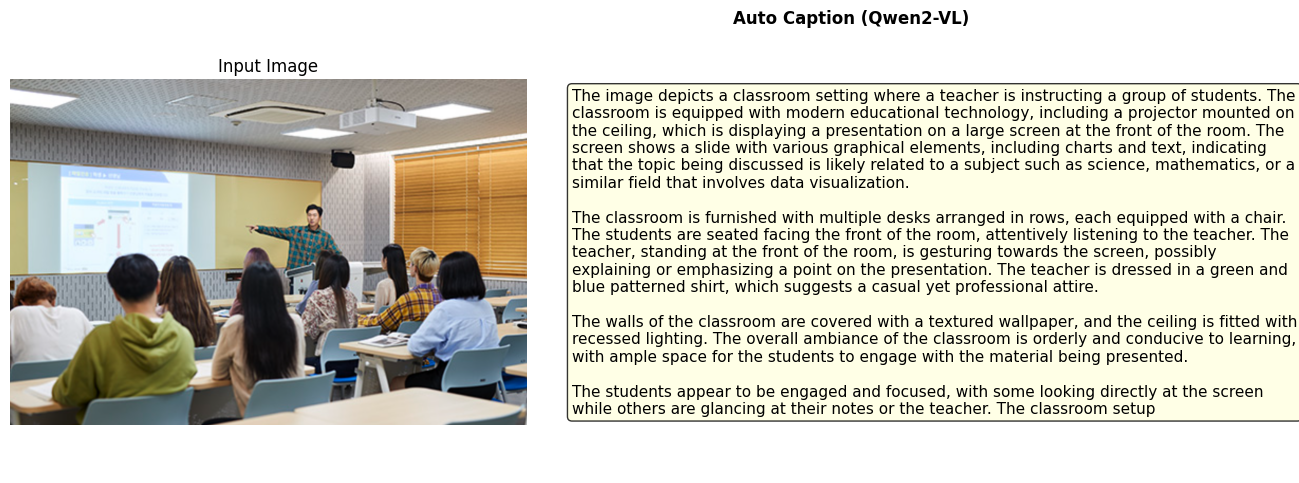


[Caption]
The image depicts a classroom setting where a teacher is instructing a group of students. The classroom is equipped with modern educational technology, including a projector mounted on the ceiling, which is displaying a presentation on a large screen at the front of the room. The screen shows a slide with various graphical elements, including charts and text, indicating that the topic being discussed is likely related to a subject such as science, mathematics, or a similar field that involves data visualization.

The classroom is furnished with multiple desks arranged in rows, each equipped with a chair. The students are seated facing the front of the room, attentively listening to the teacher. The teacher, standing at the front of the room, is gesturing towards the screen, possibly explaining or emphasizing a point on the presentation. The teacher is dressed in a green and blue patterned shirt, which suggests a casual yet professional attire.

The walls of the classroom are

In [5]:
caption = vlm.caption(image)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1, 1.2]})
axes[0].imshow(image); axes[0].axis('off'); axes[0].set_title("Input Image")
axes[1].axis('off')
axes[1].set_title("Auto Caption (Qwen2-VL)", fontweight='bold')
axes[1].text(0.05, 0.5, caption, transform=axes[1].transAxes,
             fontsize=11, va='center', wrap=True,
             bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
plt.tight_layout()
plt.show()

print("\n[Caption]")
print(caption)

## Step 4: Ask a Question (Single-turn)

Enter any question about the image.


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


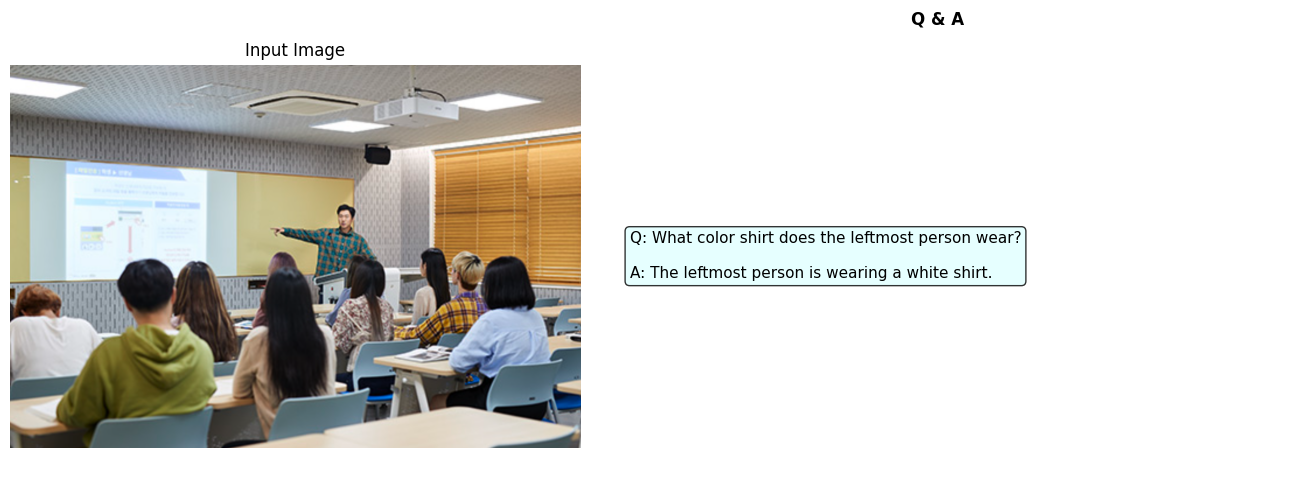

Q: What color shirt does the leftmost person wear?
A: The leftmost person is wearing a white shirt.


In [7]:
# ─── Change the question here ────────────────────────────────────────────────
QUESTION = "What color shirt does the leftmost person wear?"
# QUESTION = "How many people are in the classroom?"
# ─────────────────────────────────────────────────────────────────────────────

answer = vlm.answer(image, QUESTION)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1, 1.2]})
axes[0].imshow(image); axes[0].axis('off'); axes[0].set_title("Input Image")
axes[1].axis('off')
axes[1].set_title("Q & A", fontweight='bold')
qa_text = f"Q: {QUESTION}\n\nA: {answer}"
axes[1].text(0.05, 0.5, qa_text, transform=axes[1].transAxes,
             fontsize=11, va='center', wrap=True,
             bbox=dict(boxstyle='round', facecolor='lightcyan', alpha=0.8))
plt.tight_layout()
plt.show()

print(f"Q: {QUESTION}")
print(f"A: {answer}")